<a href="https://colab.research.google.com/github/victorcetre/Algoritmos-de-Optimizacion/blob/main/PROYECTO_(Trabajo_Pr%C3%A1ctico)_2a_Conv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algoritmos de optimización - Seminario
Nombre y Apellidos: **Victor Andres Cetre Rodriguez** y **Oscar Dario Sanchez Perez** (Grupo 41) <br>

URL: https://colab.research.google.com/drive/1WouWU-PTZAUry0JQf9YfHV0QhhUsEaF6?usp=sharing <br>

Github: https://github.com/victorcetre/Algoritmos-de-Optimizacion <br>

Convocatoria: Segunda convocatoria (2a Conv) <br>

Problema:
> 3. Combinar cifras y operaciones

Descripción del problema:

Disponemos de las 9 cifras del 1 al 9 (excluimos el cero) y de los 4 signos básicos de las operaciones fundamentales: suma (+), resta (-), multiplicación (\*) y división (/).
Debemos combinarlos alternativamente sin repetir ninguno de ellos para obtener una cantidad dada. Un ejemplo sería para obtener el 4: $4+2-6/3*1 = 4$

Debe analizarse el problema para encontrar todos los valores enteros posibles planteando las siguientes cuestiones:
- ¿Qué valor máximo y mínimo se pueden obtener según las condiciones del problema?
- ¿Es posible encontrar todos los valores enteros posibles entre dicho mínimo y máximo?

(*) La respuesta es obligatoria

In [ ]:
import itertools
import math
import random
import time
import matplotlib.pyplot as plt

CIFRAS = (1, 2, 3, 4, 5, 6, 7, 8, 9)
OPERACIONES = ('+', '-', '*', '/')
K = 5  # los 4 signos se usan una vez cada uno, intercalados entre 5 cifras (como en el ejemplo)

(*)¿Cuantas posibilidades hay sin tener en cuenta las restricciones?<br>
¿Cuantas posibilidades hay teniendo en cuenta todas las restricciones?

Respuesta

Una expresión tiene la forma `cifra op cifra op cifra op cifra op cifra`: 5 huecos para cifras y 4 para signos (al no repetir signos, como mucho hay 4, igual que en el ejemplo del enunciado).

- Sin restricciones (se pueden repetir cifras y signos): $9^5 \cdot 4^4 = 59.049 \cdot 256 = 15.116.544$
- Con restricciones (sin repetir): variaciones de 9 cifras tomadas de 5 en 5 por permutaciones de los 4 signos: $V(9,5) \cdot 4! = 15.120 \cdot 24 = 362.880$

In [ ]:
sin_restricciones = len(CIFRAS) ** K * len(OPERACIONES) ** (K - 1)
con_restricciones = math.perm(len(CIFRAS), K) * math.factorial(len(OPERACIONES))
print(f"Sin restricciones: {sin_restricciones:,}")
print(f"Con restricciones: {con_restricciones:,}")

# comprobacion contando las combinaciones que genera itertools
n_cifras = sum(1 for _ in itertools.permutations(CIFRAS, K))
n_ops = sum(1 for _ in itertools.permutations(OPERACIONES))
print(f"Comprobación con itertools: {n_cifras} x {n_ops} = {n_cifras * n_ops:,}")

Sin restricciones: 15,116,544
Con restricciones: 362,880
Comprobación con itertools: 15120 x 24 = 362,880


Modelo para el espacio de soluciones<br>
(*) ¿Cual es la estructura de datos que mejor se adapta al problema? Argumentalo.(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, argumentalo)

Respuesta

Cada solución es un par de tuplas `(cifras, operaciones)`, por ejemplo `((4, 2, 6, 3, 1), ('+', '-', '/', '*'))`. Es justo lo que devuelve `itertools.permutations`, son inmutables y ocupan poco.
Los resultados se guardan en un diccionario `valor -> expresión`, que permite comprobar en O(1) si un valor ya se ha alcanzado y quedarnos con una expresión de ejemplo para cada entero.

Al principio construimos la expresión como texto y la evaluamos con `eval`, como sugiere el enunciado. Lo cambiamos porque `eval` trabaja en coma flotante (para saber si el resultado es entero hay que comparar con una tolerancia) y porque volver a analizar el texto en cada una de las 362.880 expresiones es lento. Ahora evaluamos con enteros (numerador y denominador), así que el resultado es exacto. Abajo se comprueba que las dos formas dan lo mismo y cuál es más rápida.

In [ ]:
def evaluar(cifras, ops):
    # Evalua la expresion respetando la precedencia (* y / antes que + y -)
    # con aritmetica entera exacta. Devuelve (numerador, denominador).
    total_n, total_d = 0, 1          # suma de los terminos ya cerrados
    signo = 1                        # signo del termino actual
    term_n, term_d = cifras[0], 1    # termino actual (productos y divisiones)
    for op, c in zip(ops, cifras[1:]):
        if op == '*':
            term_n *= c
        elif op == '/':
            term_d *= c
        else:  # + o - cierran el termino actual y abren otro
            total_n = total_n * term_d + signo * term_n * total_d
            total_d *= term_d
            signo = 1 if op == '+' else -1
            term_n, term_d = c, 1
    total_n = total_n * term_d + signo * term_n * total_d
    total_d *= term_d
    return total_n, total_d


def a_texto(cifras, ops):
    # (4,2,6,3,1), ('+','-','/','*')  ->  '4+2-6/3*1'
    return str(cifras[0]) + ''.join(op + str(c) for op, c in zip(ops, cifras[1:]))


ejemplo = ((4, 2, 6, 3, 1), ('+', '-', '/', '*'))
n, d = evaluar(*ejemplo)
print(a_texto(*ejemplo), '=', n // d, '| con eval:', eval(a_texto(*ejemplo)))

# comparacion con eval sobre todo el espacio: mismo resultado y tiempo de cada uno
ops_perm = list(itertools.permutations(OPERACIONES))
t0 = time.perf_counter()
exactos = [evaluar(c, o) for c in itertools.permutations(CIFRAS, K) for o in ops_perm]
t_exacto = time.perf_counter() - t0
t0 = time.perf_counter()
flotantes = [eval(a_texto(c, o)) for c in itertools.permutations(CIFRAS, K) for o in ops_perm]
t_eval = time.perf_counter() - t0

diferencias = sum((n % d == 0) != (abs(v - round(v)) < 1e-9) for (n, d), v in zip(exactos, flotantes))
print(f"Expresiones donde eval y la evaluación exacta no coinciden en si es entero: {diferencias}")
print(f"Tiempo evaluación exacta: {t_exacto:.2f}s | tiempo con eval: {t_eval:.2f}s")

4+2-6/3*1 = 4 | con eval: 4.0


Expresiones donde eval y la evaluación exacta no coinciden en si es entero: 0
Tiempo evaluación exacta: 0.27s | tiempo con eval: 2.86s


Según el modelo para el espacio de soluciones<br>
(*)¿Cual es la función objetivo?

(*)¿Es un problema de maximización o minimización?

Respuesta

La función objetivo es el valor de la expresión: $f(cifras, ops) = c_1\, op_1\, c_2\, op_2\, c_3\, op_3\, c_4\, op_4\, c_5$, evaluada con la precedencia habitual y considerando solo los resultados enteros.

El enunciado pide el valor máximo y el mínimo, así que son dos problemas: uno de **maximización** ($\max f$) y otro de **minimización** ($\min f$). La segunda pregunta (si se alcanzan todos los enteros entre ambos) no es de optimización sino de enumeración: hay que recorrer todo el espacio y ver qué valores salen.

In [ ]:
def f(cifras, ops):
    # funcion objetivo: valor de la expresion (None si no es entero)
    n, d = evaluar(cifras, ops)
    return n // d if n % d == 0 else None

print(f(*ejemplo))
print(f((1, 2, 3, 4, 5), ('/', '+', '-', '*')))  # 1/2+3-4*5 no es entero

4
None


Diseña un algoritmo para resolver el problema por fuerza bruta

Respuesta

Recorremos todas las variaciones de 5 cifras y, para cada una, los 24 órdenes de los signos. Evaluamos cada expresión y, si el resultado es entero, lo guardamos en el diccionario. Al final el mínimo y el máximo son las claves menor y mayor.

In [ ]:
def fuerza_bruta(pool=CIFRAS):
    resultados = {}                                   # valor -> (cifras, ops)
    ops_perm = list(itertools.permutations(OPERACIONES))  # los 24 ordenes se calculan una vez
    for cifras in itertools.permutations(pool, K):
        for ops in ops_perm:
            n, d = evaluar(cifras, ops)
            if n % d == 0:
                resultados.setdefault(n // d, (cifras, ops))
    return resultados


res = fuerza_bruta()
minimo, maximo = min(res), max(res)
print(f"Máximo: {maximo}  ->  {a_texto(*res[maximo])}")
print(f"Mínimo: {minimo}  ->  {a_texto(*res[minimo])}")
print(f"Valores enteros distintos: {len(res)}")
huecos = [v for v in range(minimo, maximo + 1) if v not in res]
print(f"Enteros entre {minimo} y {maximo} que no se pueden obtener: {huecos}")

Máximo: 77  ->  7/1-2+8*9
Mínimo: -69  ->  1+4/2-8*9
Valores enteros distintos: 147
Enteros entre -69 y 77 que no se pueden obtener: []


Con las cifras del 1 al 9 el **máximo es 77** y el **mínimo es -69**, y **sí se pueden obtener todos los enteros entre -69 y 77** (los 147). Una expresión para cada uno:

In [ ]:
for v in range(minimo, maximo + 1):
    print(f"{v:>4} = {a_texto(*res[v])}", end='   ' if (v - minimo + 1) % 6 else '\n')

 -69 = 1+4/2-8*9    -68 = 1+6/2-8*9    -67 = 2/1+3-8*9    -66 = 2/1+4-8*9    -65 = 2/1+5-8*9    -64 = 2/1+6-8*9
 -63 = 2/1+7-8*9    -62 = 3/1+7-8*9    -61 = 4/1+7-8*9    -60 = 1+4/2-7*9    -59 = 1+6/2-7*9    -58 = 1-7*9+8/2
 -57 = 2/1+4-7*9    -56 = 2/1+5-7*9    -55 = 2/1+6-7*9    -54 = 3/1+6-7*9    -53 = 1+4/2-7*8    -52 = 1+6/2-7*8
 -51 = 1+4/2-6*9    -50 = 2/1+4-7*8    -49 = 1-6*9+8/2    -48 = 2/1+4-6*9    -47 = 2/1+5-6*9    -46 = 3/1+5-6*9
 -45 = 1+4/2-6*8    -44 = 1-6*8+9/3    -43 = 2/1+3-6*8    -42 = 1+4/2-5*9    -41 = 1-5*9+6/2    -40 = 1-5*9+8/2
 -39 = 1+4/2-6*7    -38 = 1-6*7+9/3    -37 = 1+4/2-5*8    -36 = 1-5*8+6/2    -35 = 2/1+3-5*8    -34 = 2/1+4-5*8
 -33 = 1-4*9+6/3    -32 = 1+3-8/2*9    -31 = 1+4-8/2*9    -30 = 1-5*7+8/2    -29 = 1-4*8+6/3    -28 = 1-4*8+6/2
 -27 = 1+4/2-5*6    -26 = 1-5*6+9/3    -25 = 1-4*7+6/3    -24 = 1+3-7/2*8    -23 = 1+3-6/2*9    -22 = 1-3*9+8/2
 -21 = 1+2-8/3*9    -20 = 1+3-6/2*8    -19 = 1+4-6/2*8    -18 = 1+2-7/3*9    -17 = 1+3-6/2*7    -16 = 1+

Calcula la complejidad del algoritmo por fuerza bruta

Respuesta

Si generalizamos a $n$ cifras disponibles, el algoritmo evalúa $V(n,5) \cdot 4! = n(n-1)(n-2)(n-3)(n-4) \cdot 24$ expresiones, y cada evaluación cuesta un número constante de operaciones (4 operaciones). Como el número de huecos (5) y de signos (4) es fijo, la complejidad es **$O(n^5)$**. Para $n = 9$ son 362.880 evaluaciones.

Medimos el tiempo para varios $n$ y lo comparamos con una curva $n^5$:

n=9:    362,880 expresiones  0.24s


n=10:    725,760 expresiones  0.48s


n=11:  1,330,560 expresiones  0.88s


n=12:  2,280,960 expresiones  1.51s


n=13:  3,706,560 expresiones  2.61s


n=14:  5,765,760 expresiones  3.84s


n=15:  8,648,640 expresiones  5.68s


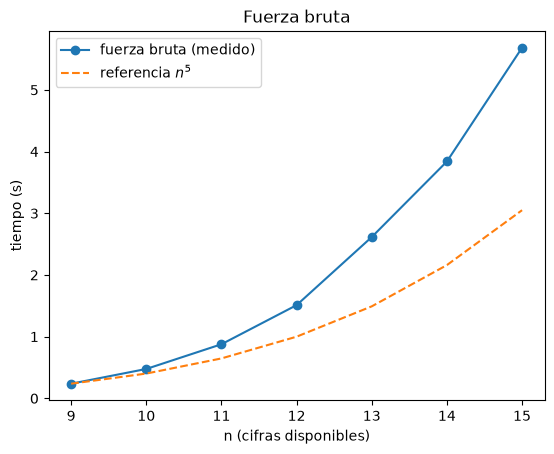

In [ ]:
n_valores = [9, 10, 11, 12, 13, 14, 15]
t_bf = []
for n in n_valores:
    t0 = time.perf_counter()
    fuerza_bruta(tuple(range(1, n + 1)))
    t_bf.append(time.perf_counter() - t0)
    print(f"n={n}: {math.perm(n, K) * 24:>10,} expresiones  {t_bf[-1]:.2f}s")

referencia = [t_bf[0] * (n / n_valores[0]) ** 5 for n in n_valores]
plt.plot(n_valores, t_bf, 'o-', label='fuerza bruta (medido)')
plt.plot(n_valores, referencia, '--', label='referencia $n^5$')
plt.xlabel('n (cifras disponibles)'); plt.ylabel('tiempo (s)')
plt.title('Fuerza bruta'); plt.legend(); plt.show()

(*)Diseña un algoritmo que mejore la complejidad del algortimo por fuerza bruta. Argumenta porque crees que mejora el algoritmo por fuerza bruta

Respuesta

Usamos **ramificación y poda** (backtracking con cota) para encontrar el máximo y el mínimo. La expresión se construye de izquierda a derecha (signo, cifra, signo, cifra...) llevando la suma de los términos ya cerrados $S$ y el término actual $T$.

En cada nodo calculamos una cota optimista de lo que todavía puede cambiar el resultado con las cifras y signos que quedan. Como cada signo solo se usa una vez, queda como mucho un `*`: el término actual puede multiplicarse como mucho por la mayor cifra libre, y los términos nuevos suman como mucho las cifras libres más grandes (más el producto de las dos mayores si queda `*`). Si ni el mejor caso puede superar el máximo encontrado ni el peor caso puede bajar del mínimo, la rama se descarta entera sin evaluarla.

Mejora a la fuerza bruta porque no recorre todo el árbol: probando primero las cifras grandes encuentra pronto buenos candidatos y luego poda la mayoría de las ramas.

In [ ]:
def poda(pool=CIFRAS):
    pool = tuple(sorted(pool, reverse=True))   # primero las cifras grandes
    mejor = {'max': None, 'min': None, 'emax': None, 'emin': None, 'nodos': 0}

    def podable(sn, sd, tn, td, signo, libres, ops):
        # cota de lo que aun puede sumar o restar la rama (S = sn/sd, T = tn/td)
        r = len(ops)                   # cifras que faltan por colocar
        top = libres[:r]               # libres esta ordenado de mayor a menor
        R = sum(top)                   # lo maximo que suman los terminos nuevos
        m = 1                          # factor maximo del termino actual
        if '*' in ops:                 # solo queda un '*'
            m = top[0]
            if r >= 2:
                R += max(0, top[0] * top[1] - top[0] - top[1])
        d = sd * td                    # se compara con enteros: x/d <= M  <=>  x <= M*d
        base = sn * td
        tm = tn * m * sd
        sup = base + (tm if signo > 0 else 0) + R * d
        inf = base - (tm if signo < 0 else 0) - (R * d if '-' in ops else 0)
        return sup <= mejor['max'] * d and inf >= mejor['min'] * d

    def rec(sn, sd, tn, td, signo, libres, ops, cifras, ops_seq):
        mejor['nodos'] += 1
        if not ops:  # expresion completa
            n, d = sn * td + signo * tn * sd, sd * td
            if n % d == 0:
                v = n // d
                if mejor['max'] is None or v > mejor['max']:
                    mejor['max'], mejor['emax'] = v, (tuple(cifras), tuple(ops_seq))
                if mejor['min'] is None or v < mejor['min']:
                    mejor['min'], mejor['emin'] = v, (tuple(cifras), tuple(ops_seq))
            return
        if mejor['max'] is not None and podable(sn, sd, tn, td, signo, libres, ops):
            return  # poda: esta rama no puede mejorar ni el maximo ni el minimo
        for op in ops:
            resto_ops = tuple(o for o in ops if o != op)
            for i, c in enumerate(libres):
                resto = libres[:i] + libres[i + 1:]
                if op == '*':
                    args = (sn, sd, tn * c, td, signo)
                elif op == '/':
                    args = (sn, sd, tn, td * c, signo)
                else:  # + o - cierran el termino actual
                    args = (sn * td + signo * tn * sd, sd * td, c, 1, 1 if op == '+' else -1)
                cifras.append(c); ops_seq.append(op)
                rec(*args, resto, resto_ops, cifras, ops_seq)
                cifras.pop(); ops_seq.pop()

    for i, c in enumerate(pool):
        rec(0, 1, c, 1, 1, pool[:i] + pool[i + 1:], ('*', '+', '/', '-'), [c], [])
    return mejor


def nodos_arbol(n):
    # nodos del arbol completo: j+1 cifras colocadas y j signos, j = 0..4
    return sum(math.perm(n, j + 1) * math.perm(4, j) for j in range(K))


r = poda()
print(f"Máximo: {r['max']}  ->  {a_texto(*r['emax'])}")
print(f"Mínimo: {r['min']}  ->  {a_texto(*r['emin'])}")
print(f"Nodos visitados: {r['nodos']:,} de {nodos_arbol(9):,} ({100 * r['nodos'] / nodos_arbol(9):.1f}%)")
print("Coincide con fuerza bruta:", (r['min'], r['max']) == (minimo, maximo))

Máximo: 77  ->  9*8+7/1-2
Mínimo: -69  ->  6/3+1-9*8
Nodos visitados: 31,227 de 441,801 (7.1%)
Coincide con fuerza bruta: True


(*)Calcula la complejidad del algoritmo

Respuesta

En el peor caso la cota podría no podar nada y se recorrería el árbol completo, que tiene $\sum_{j=0}^{4} V(n, j+1)\cdot V(4, j) = O(n^5)$ nodos. Por tanto la complejidad en el peor caso sigue siendo **$O(n^5)$**: la poda no cambia la clase de complejidad.

En la práctica sí mejora mucho, porque solo visita una fracción pequeña de los nodos y esa fracción baja a medida que crece $n$. Lo comprobamos midiendo nodos visitados y tiempo para los mismos $n$ que la fuerza bruta (y verificando que ambos dan el mismo máximo y mínimo):

n=9: nodos   31,227 de    441,801 (7.1%)  poda 0.03s  fuerza bruta 0.24s  (7x más rápido)


n=10: nodos   49,656 de    855,730 (5.8%)  poda 0.05s  fuerza bruta 0.48s  (10x más rápido)


n=11: nodos   83,262 de  1,532,971 (5.4%)  poda 0.08s  fuerza bruta 0.88s  (11x más rápido)


n=12: nodos  113,194 de  2,582,460 (4.4%)  poda 0.12s  fuerza bruta 1.51s  (13x más rápido)


n=13: nodos  178,734 de  4,139,629 (4.3%)  poda 0.17s  fuerza bruta 2.61s  (15x más rápido)


n=14: nodos  224,982 de  6,369,286 (3.5%)  poda 0.28s  fuerza bruta 3.84s  (14x más rápido)


n=15: nodos  302,808 de  9,468,495 (3.2%)  poda 0.32s  fuerza bruta 5.68s  (18x más rápido)


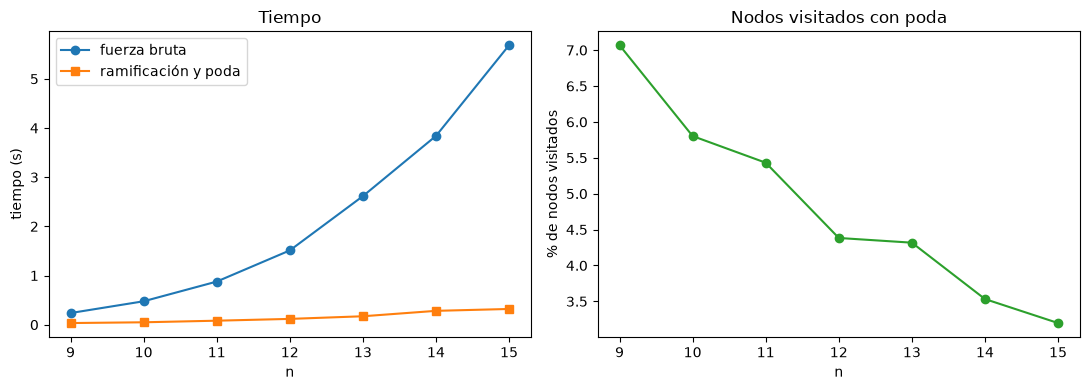

In [ ]:
t_poda, porcentaje = [], []
for n, tb in zip(n_valores, t_bf):
    pool = tuple(range(1, n + 1))
    t0 = time.perf_counter()
    r = poda(pool)
    t_poda.append(time.perf_counter() - t0)
    porcentaje.append(100 * r['nodos'] / nodos_arbol(n))
    bf = fuerza_bruta(pool)
    assert (r['min'], r['max']) == (min(bf), max(bf))
    print(f"n={n}: nodos {r['nodos']:>8,} de {nodos_arbol(n):>10,} ({porcentaje[-1]:.1f}%)"
          f"  poda {t_poda[-1]:.2f}s  fuerza bruta {tb:.2f}s  ({tb / t_poda[-1]:.0f}x más rápido)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(n_valores, t_bf, 'o-', label='fuerza bruta')
ax1.plot(n_valores, t_poda, 's-', label='ramificación y poda')
ax1.set_xlabel('n'); ax1.set_ylabel('tiempo (s)'); ax1.set_title('Tiempo'); ax1.legend()
ax2.plot(n_valores, porcentaje, 'o-', color='tab:green')
ax2.set_xlabel('n'); ax2.set_ylabel('% de nodos visitados'); ax2.set_title('Nodos visitados con poda')
plt.tight_layout(); plt.show()

Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

Respuesta

Generalizamos el problema: en lugar de las cifras 1 a 9 usamos $n$ números positivos distintos elegidos al azar. Usamos `random.sample` para que no haya repetidos (restricción del enunciado) y una semilla para que los resultados se puedan repetir. Probamos el caso mínimo ($n=5$, sin elección de cifras), tamaños medianos y un rango de valores más amplio.

In [ ]:
def generar_pool(n, valor_max=20, semilla=None):
    # n numeros distintos entre 1 y valor_max
    rnd = random.Random(semilla)
    return tuple(sorted(rnd.sample(range(1, valor_max + 1), n)))


juegos = {
    'enunciado (1..9)':        CIFRAS,
    'n=5 (mínimo)':            generar_pool(5, semilla=1),
    'n=9 entre 1 y 20':        generar_pool(9, semilla=2),
    'n=12 entre 1 y 20':       generar_pool(12, semilla=3),
    'n=10 entre 1 y 100':      generar_pool(10, valor_max=100, semilla=4),
}
for nombre, pool in juegos.items():
    print(f"{nombre:22s} {pool}")

enunciado (1..9)       (1, 2, 3, 4, 5, 6, 7, 8, 9)
n=5 (mínimo)           (3, 4, 5, 9, 19)
n=9 entre 1 y 20       (2, 3, 5, 6, 11, 12, 13, 17, 19)
n=12 entre 1 y 20      (1, 2, 5, 8, 10, 11, 12, 14, 15, 18, 19, 20)
n=10 entre 1 y 100     (3, 9, 12, 14, 20, 31, 39, 51, 62, 93)


Aplica el algoritmo al juego de datos generado

Respuesta

Aplicamos los dos algoritmos a cada juego de datos, comprobamos que dan el mismo máximo y mínimo y contamos cuántos enteros entre ambos no se pueden obtener (huecos).

In [ ]:
resumen = {}
for nombre, pool in juegos.items():
    t0 = time.perf_counter(); bf = fuerza_bruta(pool); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); r = poda(pool); tp = time.perf_counter() - t0
    mn, mx = min(bf), max(bf)
    huecos = [v for v in range(mn, mx + 1) if v not in bf]
    resumen[nombre] = (bf, mn, mx)
    ok = 'OK' if (r['min'], r['max']) == (mn, mx) else 'DISTINTO'
    print(f"{nombre:22s} min={mn:>6} max={mx:>6} huecos={len(huecos):>5} "
          f"t_bruta={tb:.2f}s t_poda={tp:.3f}s {ok}")
    print(f"{'':22s} max: {a_texto(*r['emax'])}   min: {a_texto(*r['emin'])}")

enunciado (1..9)       min=   -69 max=    77 huecos=    0 t_bruta=0.23s t_poda=0.031s OK
                       max: 9*8+7/1-2   min: 6/3+1-9*8
n=5 (mínimo)           min=   -88 max=    96 huecos=  167 t_bruta=0.00s t_poda=0.003s OK
                       max: 19*5+4-9/3   min: 9/3+4-19*5


n=9 entre 1 y 20       min=  -319 max=   334 huecos=  181 t_bruta=0.24s t_poda=0.034s OK
                       max: 19*17+13-12/6   min: 12/6+2-19*17


n=12 entre 1 y 20      min=  -377 max=   396 huecos=   16 t_bruta=1.54s t_poda=0.110s OK
                       max: 20*19+18/1-2   min: 10/5+1-20*19


n=10 entre 1 y 100     min= -5753 max=  5814 huecos= 8957 t_bruta=0.50s t_poda=0.047s OK
                       max: 93*62+51-9/3   min: 12/3+9-93*62


Con las cifras del enunciado no hay huecos, pero con otros conjuntos sí: si los números son grandes o están muy separados, el rango entre mínimo y máximo crece mucho más rápido que la cantidad de enteros distintos que se pueden formar. En el gráfico, cada línea es un entero del rango (azul si se alcanza, rojo si no):

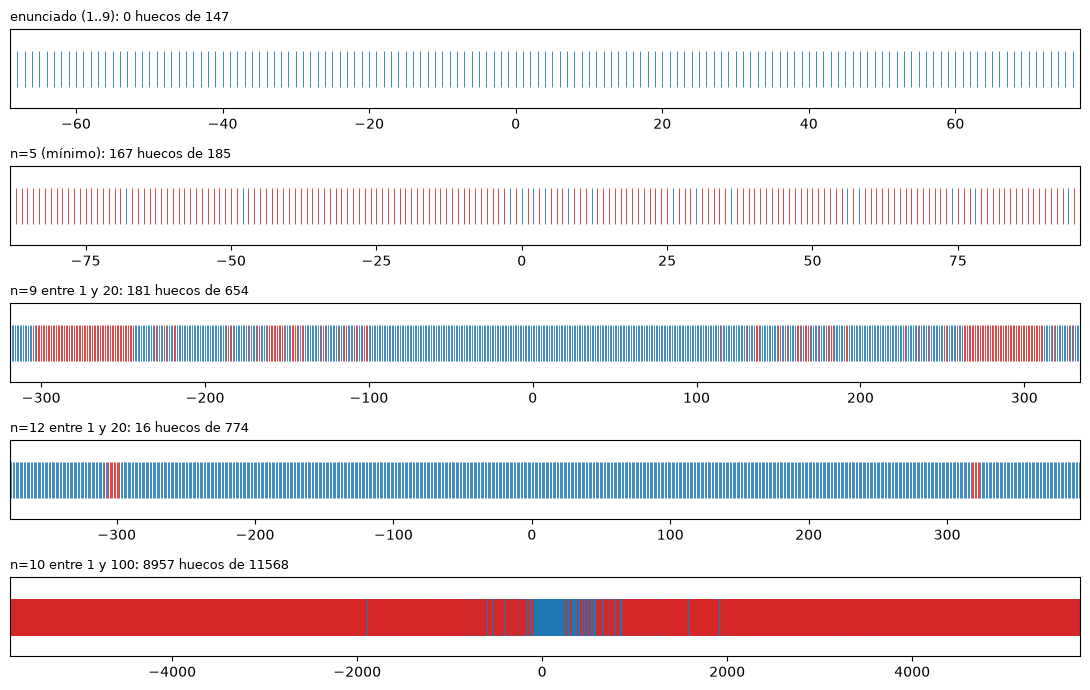

In [ ]:
fig, axes = plt.subplots(len(resumen), 1, figsize=(11, 1.4 * len(resumen)))
for ax, (nombre, (bf, mn, mx)) in zip(axes, resumen.items()):
    alcanzados = [v for v in range(mn, mx + 1) if v in bf]
    no_alcanzados = [v for v in range(mn, mx + 1) if v not in bf]
    ax.eventplot(alcanzados, colors='tab:blue', linewidths=0.6)
    if no_alcanzados:
        ax.eventplot(no_alcanzados, colors='tab:red', linewidths=0.6)
    ax.set_yticks([]); ax.set_xlim(mn, mx)
    ax.set_title(f"{nombre}: {len(no_alcanzados)} huecos de {mx - mn + 1}", fontsize=9, loc='left')
plt.tight_layout(); plt.show()

Enumera las referencias que has utilizado(si ha sido necesario) para llevar a cabo el trabajo

Respuesta

- Material de la asignatura 03MIAR Algoritmos de Optimización (VIU): enunciado del trabajo práctico y sesiones sobre complejidad y ramificación y poda.
- Guerequeta, R., y Vallecillo, A. (2000). *Técnicas de diseño de algoritmos*, capítulo de ramificación y poda. http://www.lcc.uma.es/~av/Libro/indice.html
- Documentación de Python: `itertools.permutations`, `math.perm`, `math.factorial` y `random.sample`. https://docs.python.org/3/library/itertools.html

Describe brevemente las lineas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

Respuesta

- **Buscar una cantidad dada**: el enunciado habla de obtener un valor concreto. Se puede usar la misma búsqueda con poda parando en la primera solución, o *meet in the middle* (precalcular las mitades de la expresión y cruzarlas con un diccionario).
- **Permitir paréntesis**: el número de expresiones crece mucho (formas de agrupar según los números de Catalan) y aparecen más valores; habría que pasar a programación dinámica sobre subconjuntos de cifras.
- **Usar menos signos o permitir repetirlos**: cambia el espacio de soluciones (por ejemplo, con repetición son 15 millones de expresiones) y la cota de la poda, que ahora aprovecha que solo hay un `*`.
- **Aumentar el tamaño**: con más cifras disponibles o con números grandes la fuerza bruta deja de ser viable ($O(n^5)$ con constantes altas). Se podría mejorar la cota, paralelizar la búsqueda o usar metaheurísticas (búsqueda local, recocido simulado) cuando solo interesan el máximo y el mínimo.